# Visium HD mouse small intestine

In [1]:
from pathlib import Path
import cellman.spatial as cms

ROOT        = "/bce/groups/pnucolab/analysis/l202255179/UNNAMED"
VISIUM_DIR  = f"{ROOT}/cellman_paper/data/visiumhd_enact"                       # 10x outs/ (binned_outputs/)
FULLRES     = f"{VISIUM_DIR}/Visium_HD_Mouse_Small_Intestine_tissue_image.btf"  # brightfield H&E full-res

STORE   = f"{ROOT}/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine"
SDATA   = f"{STORE}/visiumhd_small_intestine.sdata.zarr"   # unified input+output SpatialData
SCRIPTS = f"{ROOT}/CeLLMan/cellman/spatial/scripts"

SPECIES, ORGAN = "mouse", "small_intestine"   # Cell-Ontology wing for the gene panel
ONTO_API   = "https://cellman.pnucolab.com"   # Cell-Ontology KG server (public); None → HVG-only (with clean CELLONTO_* env)
DEVICE     = "cuda:1"                          # NOTE: CUDA 0 = RTX 4090 (opposite of nvidia-smi)
NCORES     = 30

# vector-field geometry
BIN_UM        = 2      # rasterization grid (µm); Visium HD native square = 2 µm
BANDWIDTH_UM  = 2.5      # Gaussian blur bandwidth (µm); segfree sweet spot ≈ 2 µm
SIGMA_BIN     = BANDWIDTH_UM / BIN_UM          # σ in bin units
SAMPLING_DIST = 1.0    # sampling distance (µm)
HVG_N         = 5000

Path(STORE).mkdir(parents=True, exist_ok=True)
print("cellman.spatial", cms.__version__, "| store:", STORE)

cellman.spatial 0.1.0 | store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 1 — Load Visium HD → `GridDataset` (unified SpatialData)

`load_visiumhd` reads the `binned_outputs/square_002um` counts + full-res H&E via
`spatialdata_io.visium_hd`, keeps in-tissue bins, converts `obsm['spatial']` to µm, fits the
lattice→pixel affine, and returns a uniform SpatialData (`tables['table']` + `images['staining']`).
Brightfield H&E is tissue-on-light, so `he_revert=True` is set internally.

In [2]:
import spatialdata as sd
if Path(SDATA).exists():
    sdata = sd.read_zarr(SDATA); print("loaded existing sdata:", SDATA)
else:
    sdata = cms.load_visiumhd(VISIUM_DIR, species=SPECIES, organ=ORGAN,
                              bin_um=BIN_UM, fullres_image_file=FULLRES)
    sdata.write(SDATA)   # persist unified input (tables['table'] + images['staining']); one-time
grid = cms.GridDataset.from_sdata(sdata)   # lightweight view for HVG / panel
print("sdata:", dict(tables=list(sdata.tables), images=list(sdata.images)))
print("bins:", grid.raw.n_obs, "| genes:", grid.n_genes,
      "| origin µm:", tuple(round(v, 1) for v in grid.origin))

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'Visium_HD_Mouse_Small_Intestine_square_002um', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


loaded existing sdata: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/visiumhd_small_intestine.sdata.zarr
sdata: {'tables': ['table'], 'images': ['staining']}
bins: 5479660 | genes: 19059 | origin µm: (np.float64(262.0), np.float64(120.0))


In [3]:
sdata

SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/visiumhd_small_intestine.sdata.zarr
├── Images
│     └── 'staining': DataArray[cyx] (3, 21943, 23618)
└── Tables
      └── 'table': AnnData (5479660, 19059)
with coordinate systems:
    ▸ 'global', with elements:
        staining (Images)

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'Visium_HD_Mouse_Small_Intestine_square_002um', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'Visium_HD_Mouse_Small_Intestine_square_002um', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


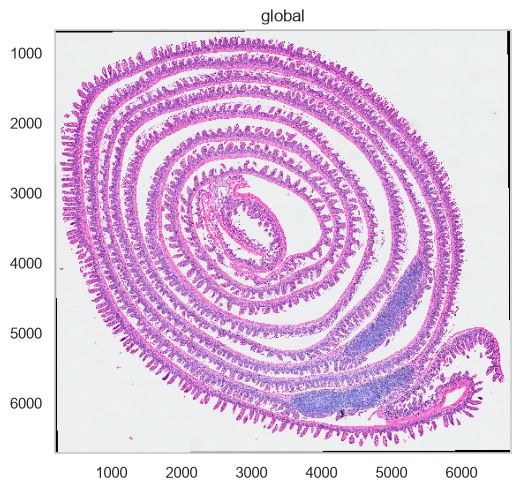

In [4]:
import spatialdata_plot

sdata.pl.render_images('staining').pl.show()

## Step 2 — Gene panel = HVG ∪ Cell-Ontology markers

HVG is estimated directly on the native 2 µm bins (Visium HD is already binned, so no coarse
re-aggregation is needed); ontology markers for `mouse/small_intestine` are unioned in. If the
KG server is unreachable this degrades to HVG-only automatically.

In [5]:
panel, onto_markers = cms.select_gene_panel(
    grid.raw, SPECIES, ORGAN, hvg_n=HVG_N, server_url=ONTO_API)
print("panel genes:", len(panel), "| ontology markers in panel:", len(onto_markers))

[panel] HVG (seurat_v3 on 100000 bins, denylist-filtered): 4996
[panel] slim-index mouse/small_intestine: n_terms=68 version=2026-07-29 → 302 marker genes
[panel] final panel: 5173 genes (HVG 4996 ∪ ontology-in-data 293)
panel genes: 5173 | ontology markers in panel: 293


## Step 3 — `compute_vf` (rasterize + GPU blur)

Aggregates the panel counts to a `BIN_UM` grid and Gaussian-blurs into `vf_normalized`
(bandwidth = `SIGMA_BIN * BIN_UM` µm). Only the normalized field is persisted.

In [ ]:
ds = cms.Dataset(STORE)
analysis = cms.Analysis(ds, ncores=NCORES, verbose=True)

zarr keys: ['visiumhd_small_intestine.sdata.zarr']


In [8]:
analysis.compute_vf(sdata, bin_um=BIN_UM, panel=panel,
                    sampling_distance=SAMPLING_DIST, sigma_bin=SIGMA_BIN, device=DEVICE)

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=12, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
compute_vf (blur, tiled): 100%|██████████| 52/52 [01:47<00:00,  2.07s/it]


[compute_vf] blur raster (3285, 3191)@2µm → vf (5173, 3285, 3191)@2.0µm (stride 1, compute tile 64×512, store chunk 32×32, radius 6, bandwidth 2.5µm, fp32)


AnnData object with n_obs × n_vars = 5479660 × 5173
    obs: 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'bin_size_um', 'grid_origin_um'
    obsm: 'spatial'

## Step 4 — `downsample_vector` (count lookup)

Samples voxels from the H&E tissue mask and looks them up in the blur field (`grid=` count
path; no KDE). Brightfield H&E is tissue-on-light, so `GridDataset.he_revert=True` inverts
before thresholding.

In [9]:
adata = analysis.downsample_vector(sdata, n_samples_per_block=5, block_um=10,
                                   vf_norm_percentile=25)
adata

downsample_vector (lookup, 6181 tiles, 30w): 100%|██████████| 6181/6181 [00:33<00:00, 186.15it/s]


[downsample] otsu=69.57 mask_px=192249295 sampled=720408 kept(vf_norm>2.327)=658034


AnnData object with n_obs × n_vars = 658034 × 5173
    obs: 'vf_norm'
    obsm: 'spatial'

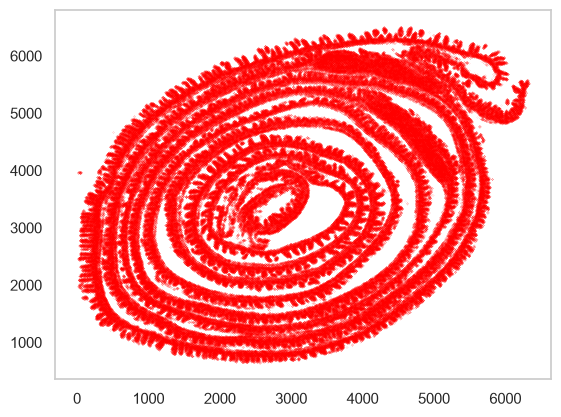

In [10]:
ds.plot_downsampled_vector(s=0.01)

## Step 5 — Clustering

In [12]:
import rapids_singlecell as rsc

rsc.pp.pca(adata, n_comps=50)
rsc.pp.neighbors(adata, n_neighbors=15)
rsc.tl.leiden(adata, resolution=1)

In [13]:
adata

AnnData object with n_obs × n_vars = 658034 × 5173
    obs: 'vf_norm', 'leiden'
    uns: 'pca', 'neighbors', 'leiden'
    obsm: 'spatial', 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [14]:
adata.write_h5ad(f"{STORE}/mouse_small_intestine_cls.h5ad")

## Step 6 — Agentic annotation 

/annotate-mode Annotate the h5ad below using the annotate-expert agent.

- input : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/mouse_small_intestine_cls.h5ad
- out : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine
- tissue : mouse, small intestine
- virtual env : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv
- cluster column : leiden 
- note : use 5090 GPU on device '1'

/tmp/ipykernel_1900564/3787947187.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)


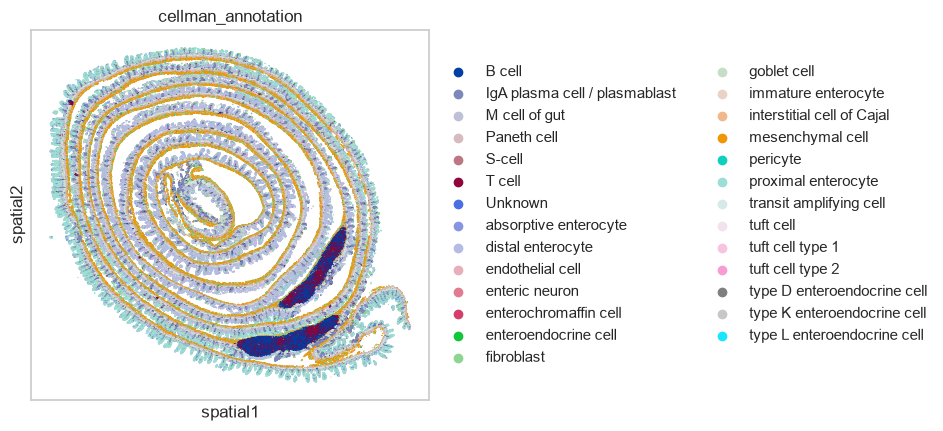

In [14]:
import scanpy as sc

ANNO = f"{STORE}/annotation_out/mouse_small_intestine_cls_annotated.h5ad" 
if Path(ANNO).exists():
    anno = sc.read_h5ad(ANNO)
    sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)
else:
    anno = None
    print("annotation not found yet — run annotate-mode to produce:", ANNO)

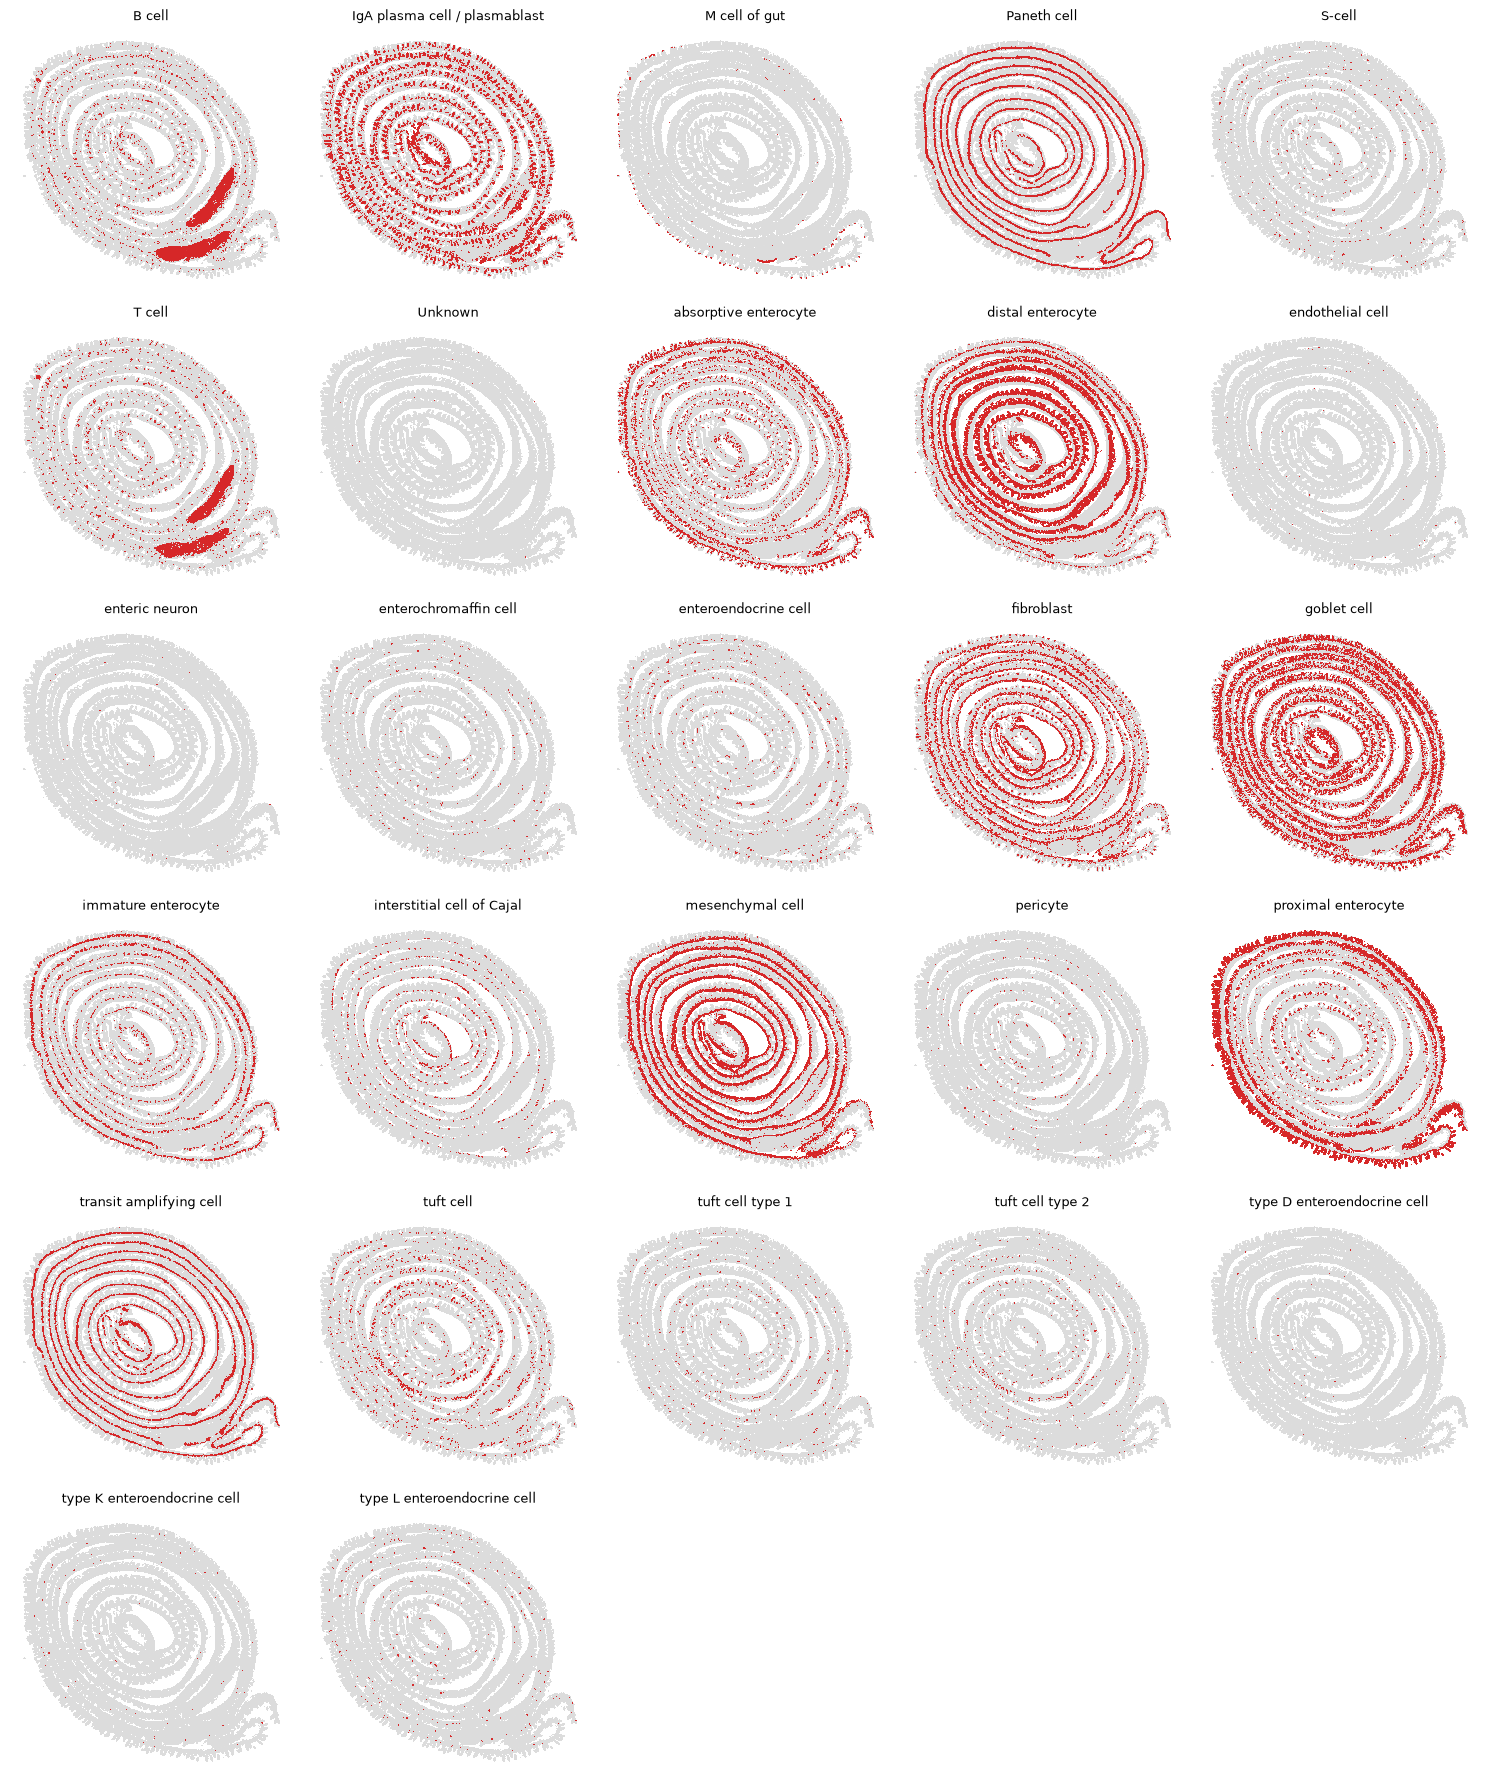

In [11]:
import math, matplotlib.pyplot as plt
COL='cellman_annotation'; PS=0.5; N_COLS=5; BG='#dcdcdc'; FG='#d62728'
xy = anno.obsm['spatial']; labels = anno.obs[COL].astype(str).to_numpy()
cats = list(anno.obs[COL].cat.categories); n=len(cats)
n_cols=min(N_COLS,n); n_rows=math.ceil(n/n_cols)
fig,axes=plt.subplots(n_rows,n_cols,figsize=(3*n_cols,3*n_rows),squeeze=False)
for a_ in axes.flat: a_.set_axis_off()
for i,ct in enumerate(cats):
    a_=axes[i//n_cols,i%n_cols]; m=labels==ct
    a_.scatter(xy[~m,0],xy[~m,1],s=PS,c=BG,linewidths=0,rasterized=True)
    a_.scatter(xy[m,0], xy[m,1], s=PS,c=FG,linewidths=0,rasterized=True)
    a_.set_title(ct,fontsize=9); a_.set_aspect('equal'); a_.invert_yaxis()
fig.tight_layout(); plt.show()

In [2]:
ds = cms.Dataset(STORE)
analysis = cms.Analysis(ds, ncores=NCORES, verbose=True)

zarr keys: ['celltype_maps', 'celltype_names', 'centroids', 'cluster_labels', 'coordinate_bounds', 'coordinate_offset', 'downsampled_global_xy', 'downsampled_vectors', 'downsampled_vf_norm', 'filtered_celltype_maps', 'genes', 'kde_computed', 'map_corr.zarr', 'map_ind.zarr', 'max_correlations', 'max_probabilities', 'normalized_vectors', 'original_coordinate_bounds', 'tsvm_field_pca', 'tsvm_pca_comps', 'tsvm_pca_mean', 'tsvm_rff_beta', 'tsvm_rff_omega', 'vf_norm', 'vf_normalized', 'vf_params', 'visiumhd_small_intestine.sdata.zarr']


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at annotation_out is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at celltype_index.csv is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at mouse_small_intestine_cls.h5ad is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at corr is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


Loaded existing KDE results.
Loaded existing local maxima.
Loaded a precomputed normalized vector.
Loaded existing gene list.
Loaded a precomputed normalized vector field.
Loaded existing cluster labels.
Loaded existing cell type maps.
Loaded existing filtered cell type maps.


In [3]:
import spatialdata as sd
sdata = sd.read_zarr(SDATA)
sdata

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/spatialdata/_core/spatialdata.py:170: UserWarning: The table is annotating 'Visium_HD_Mouse_Small_Intestine_square_002um', which is not present in the SpatialData object.
  self.validate_table_in_spatialdata(v)


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/visiumhd_small_intestine.sdata.zarr
├── Images
│     └── 'staining': DataArray[cyx] (3, 21943, 23618)
└── Tables
      └── 'table': AnnData (5479660, 19059)
with coordinate systems:
    ▸ 'global', with elements:
        staining (Images)

In [4]:
ANNO = f"{STORE}/annotation_out/mouse_small_intestine_cls_annotated.h5ad" 

In [7]:
sdata_ind = analysis.map_celltypes(sdata,
    method='tsvm', gpu_device=DEVICE, h5ad=ANNO,   # h5ad는 store에 이미 있으면 생략 가능
    map_kwargs={'fit_kwargs': {
        'algo': 'soft',               # ★ 옛 방식 (S3VM, label-switching 아님)
        'use_unlabeled': True,
        'unlabeled_source': 'field',  # 전체 필드에서 랜덤샘플 ('cache'도 가능=PCA캐시서 샘플)
        'n_unlabeled': 200000,        # 샘플 크기
        'kernel': 'rbf', 'n_components': 50, 'rff_dim': 1024,
        'ent': 0.3, 'balance': 2.0,   # soft 엔트로피/밸런스 페널티 (조정 가능)
        # max_fit_cells=200000 기본(OOM 방지)
    }})

sdata_ind

[map_celltypes] building centroids from mouse_small_intestine_cls_annotated.h5ad: 36 celltypes, 658034 vectors
    id=  0  fibroblast                        [celltype]  (37821 vectors)
    id=  1  interstitial cell of Cajal        [celltype]  (5034 vectors)
    id=  2  mesenchymal cell                  [celltype]  (74850 vectors)
    id=  3  pericyte                          [celltype]  (811 vectors)
    id=  4  B cell                            [celltype]  (28045 vectors)
    id=  5  IgA plasma cell / plasmablast     [celltype]  (70647 vectors)
    id=  6  T cell                            [celltype]  (19879 vectors)
    id=  7  distal enterocyte                 [celltype]  (119415 vectors)
    id=  8  goblet cell                       [celltype]  (68877 vectors)
    id=  9  tuft cell                         [celltype]  (7380 vectors)
    id= 10  tuft cell type 1                  [celltype]  (953 vectors)
    id= 11  tuft cell type 2                  [celltype]  (1187 vectors)
    id=

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=29, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


[map_celltypes] wrote cluster_labels (658034,) + centroids (36, 5173) + celltype_names (36) + colors (normalized_vectors untouched)
[map_celltypes] wrote /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/celltype_index.csv
[fit] subsampled labeled 658034 -> 200003 for fitting (max_fit_cells=200000; stratified, seeded)
[fit] labeled=(200003, 5173)  k=36  pca=50  thr=2.3271
[fit] loaded persisted PCA basis (row-normalized)
[cache] reuse tsvm_field_pca (fp match)


sample_unlabeled:   0%|          | 0/26 [00:09<?, ?it/s, have=272874]


[fit] unlabeled sample=(200000, 50) source=field
[fit] gamma (median heuristic) = 0.50954
[fit] RBF via RFF: d=50 -> D=1024  labeled=(200003, 1024)
  anneal 1/4  w_u=0.00  loss=0.7583
  anneal 2/4  w_u=0.33  loss=0.9265
  anneal 3/4  w_u=0.67  loss=1.1542
  anneal 4/4  w_u=1.00  loss=1.2473
[fit] algo=soft  train_acc=0.7261  abstain_q=0.0 (off at map time; filtering is filter_celltypemaps' job)
[map] kernel=rbf (RFF D=1024, gamma=0.5095396273004383)
[cache] reuse tsvm_field_pca (fp match)


map_celltypes_tsvm[cache]: 100%|██████████| 26/26 [00:06<00:00,  3.90it/s]


[map] assigned 6030915 voxels (tau_conf=-1.000)
[map_celltypes] tables['cellman_downsampled'] (658034, 5173) 36 celltypes


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/visiumhd_small_intestine.sdata.zarr
├── Images
│     └── 'staining': DataArray[cyx] (3, 21943, 23618)
└── Tables
      ├── 'cellman_downsampled': AnnData (658034, 5173)
      └── 'table': AnnData (5479660, 19059)
with coordinate systems:
    ▸ 'global', with elements:
        staining (Images)
with the following elements not in the Zarr store:
    ▸ cellman_downsampled (Tables)

In [8]:
sdata_ind = analysis.filter_celltypemaps(sdata_ind, min_p=0)
sdata_ind

[write_celltype_map] labels['cellman_celltype_map'] (3285, 3191) + images['cellman_celltype_map_rgb'] (36 celltypes) @ 2.0µm/px, origin=(262.0,120.0)


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/visiumhd_small_intestine.sdata.zarr
├── Images
│     ├── 'cellman_celltype_map_rgb': DataArray[cyx] (3, 3285, 3191)
│     └── 'staining': DataArray[cyx] (3, 21943, 23618)
├── Labels
│     └── 'cellman_celltype_map': DataArray[yx] (3285, 3191)
└── Tables
      ├── 'cellman_downsampled': AnnData (658034, 5173)
      └── 'table': AnnData (5479660, 19059)
with coordinate systems:
    ▸ 'global', with elements:
        cellman_celltype_map_rgb (Images), staining (Images), cellman_celltype_map (Labels)
with the following elements not in the Zarr store:
    ▸ cellman_celltype_map_rgb (Images)
    ▸ cellman_celltype_map (Labels)
    ▸ cellman_downsampled (Tables)

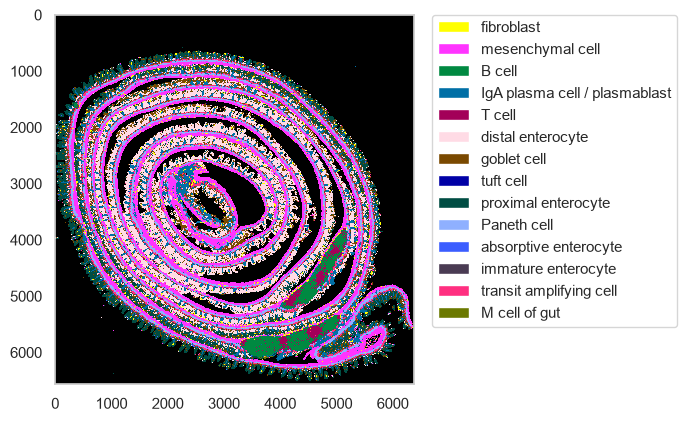

In [9]:
ds.plot_celltypes_map(show_annotation=True)

In [13]:
sdata_ind.write('/bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/map_ind.zarr')


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the

In [6]:
sdata_corr = analysis.map_celltypes(sdata,
    method='corr', h5ad=ANNO, gpu_device=DEVICE)
sdata_corr

[map_celltypes] building centroids from mouse_small_intestine_cls_annotated.h5ad: 36 celltypes, 658034 vectors
    id=  0  fibroblast                        [celltype]  (37821 vectors)
    id=  1  interstitial cell of Cajal        [celltype]  (5034 vectors)
    id=  2  mesenchymal cell                  [celltype]  (74850 vectors)
    id=  3  pericyte                          [celltype]  (811 vectors)
    id=  4  B cell                            [celltype]  (28045 vectors)
    id=  5  IgA plasma cell / plasmablast     [celltype]  (70647 vectors)
    id=  6  T cell                            [celltype]  (19879 vectors)
    id=  7  distal enterocyte                 [celltype]  (119415 vectors)
    id=  8  goblet cell                       [celltype]  (68877 vectors)
    id=  9  tuft cell                         [celltype]  (7380 vectors)
    id= 10  tuft cell type 1                  [celltype]  (953 vectors)
    id= 11  tuft cell type 2                  [celltype]  (1187 vectors)
    id=

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=29, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


[map_celltypes] wrote cluster_labels (658034,) + centroids (36, 5173) + celltype_names (36) + colors (normalized_vectors untouched)
[map_celltypes] wrote /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/celltype_index.csv


map_celltypes (corr): 100%|██████████| 26/26 [06:13<00:00, 14.36s/it]


[map_corr] assigned 4523186 voxels (thr=2.327)
[map_celltypes] tables['cellman_downsampled'] (658034, 5173) 36 celltypes


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/visiumhd_small_intestine.sdata.zarr
├── Images
│     └── 'staining': DataArray[cyx] (3, 21943, 23618)
└── Tables
      ├── 'cellman_downsampled': AnnData (658034, 5173)
      └── 'table': AnnData (5479660, 19059)
with coordinate systems:
    ▸ 'global', with elements:
        staining (Images)
with the following elements not in the Zarr store:
    ▸ cellman_downsampled (Tables)

In [7]:
sdata_corr = analysis.filter_celltypemaps(sdata_corr, min_r=0)
sdata_corr

[write_celltype_map] labels['cellman_celltype_map'] (3285, 3191) + images['cellman_celltype_map_rgb'] (36 celltypes) @ 2.0µm/px, origin=(262.0,120.0)


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/visiumhd_small_intestine.sdata.zarr
├── Images
│     ├── 'cellman_celltype_map_rgb': DataArray[cyx] (3, 3285, 3191)
│     └── 'staining': DataArray[cyx] (3, 21943, 23618)
├── Labels
│     └── 'cellman_celltype_map': DataArray[yx] (3285, 3191)
└── Tables
      ├── 'cellman_downsampled': AnnData (658034, 5173)
      └── 'table': AnnData (5479660, 19059)
with coordinate systems:
    ▸ 'global', with elements:
        cellman_celltype_map_rgb (Images), staining (Images), cellman_celltype_map (Labels)
with the following elements not in the Zarr store:
    ▸ cellman_downsampled (Tables)
    ▸ cellman_celltype_map (Labels)
    ▸ cellman_celltype_map_rgb (Images)

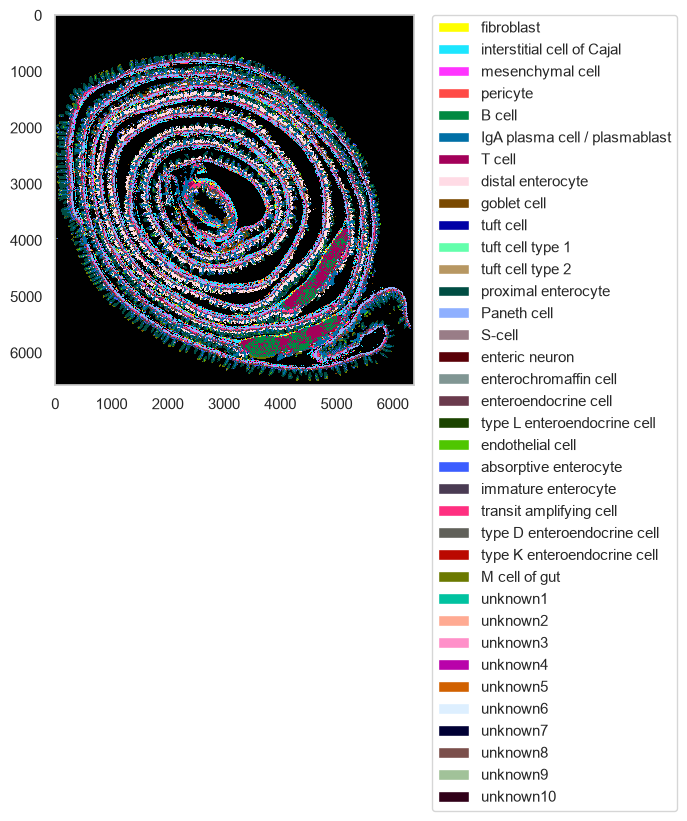

In [8]:
ds.plot_celltypes_map(show_annotation=True)

In [9]:
sdata_corr.write('/bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/map_corr.zarr')


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the

In [5]:
sdata_tsvm = analysis.map_celltypes(sdata, method="tsvm", gpu_device=DEVICE, h5ad=ANNO)

[map_celltypes] building centroids from mouse_small_intestine_cls_annotated.h5ad: 36 celltypes, 658034 vectors
    id=  0  fibroblast                        [celltype]  (37821 vectors)
    id=  1  interstitial cell of Cajal        [celltype]  (5034 vectors)
    id=  2  mesenchymal cell                  [celltype]  (74850 vectors)
    id=  3  pericyte                          [celltype]  (811 vectors)
    id=  4  B cell                            [celltype]  (28045 vectors)
    id=  5  IgA plasma cell / plasmablast     [celltype]  (70647 vectors)
    id=  6  T cell                            [celltype]  (19879 vectors)
    id=  7  distal enterocyte                 [celltype]  (119415 vectors)
    id=  8  goblet cell                       [celltype]  (68877 vectors)
    id=  9  tuft cell                         [celltype]  (7380 vectors)
    id= 10  tuft cell type 1                  [celltype]  (953 vectors)
    id= 11  tuft cell type 2                  [celltype]  (1187 vectors)
    id=

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=29, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


[map_celltypes] wrote cluster_labels (658034,) + centroids (36, 5173) + celltype_names (36) + colors (normalized_vectors untouched)
[map_celltypes] wrote /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/celltype_index.csv
[fit] subsampled labeled 658034 -> 200003 for fitting (max_fit_cells=200000; stratified, seeded)
[fit] labeled=(200003, 5173)  k=36  pca=50  thr=2.3271
[fit] loaded persisted PCA basis (row-normalized)
[cache] reuse tsvm_field_pca (fp match)
[fit] transductive pool = FULL field (5575157, 50) (train-floor=0.2037)
[fit] gamma (median heuristic) = 0.50954
[fit] RBF via RFF: d=50 -> D=1024  labeled=(200003, 1024)
  [ls] anneal 1/4 Cu=0.00 round 1: switched=8.79%  train_acc=0.7284
  [ls] anneal 1/4 Cu=0.00 round 2: switched=10.51%  train_acc=0.7182
  [ls] anneal 1/4 Cu=0.00 round 3: switched=9.99%  train_acc=0.7229
  [ls] anneal 1/4 Cu=0.00 round 4: switched=6.49%  train_acc=0.7222
  [ls] anneal 2/4 Cu=0.33 round 1: switc

map_celltypes_tsvm[cache]: 100%|██████████| 26/26 [00:06<00:00,  4.01it/s]


[map] assigned 6030915 voxels (tau_conf=-1.000)
[map_celltypes] tables['cellman_downsampled'] (658034, 5173) 36 celltypes


In [6]:
sdata_tsvm = analysis.filter_celltypemaps(sdata_tsvm, min_p=0)
sdata_tsvm

[write_celltype_map] labels['cellman_celltype_map'] (3285, 3191) + images['cellman_celltype_map_rgb'] (36 celltypes) @ 2.0µm/px, origin=(262.0,120.0)


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/visiumhd_small_intestine.sdata.zarr
├── Images
│     ├── 'cellman_celltype_map_rgb': DataArray[cyx] (3, 3285, 3191)
│     └── 'staining': DataArray[cyx] (3, 21943, 23618)
├── Labels
│     └── 'cellman_celltype_map': DataArray[yx] (3285, 3191)
└── Tables
      ├── 'cellman_downsampled': AnnData (658034, 5173)
      └── 'table': AnnData (5479660, 19059)
with coordinate systems:
    ▸ 'global', with elements:
        cellman_celltype_map_rgb (Images), staining (Images), cellman_celltype_map (Labels)
with the following elements not in the Zarr store:
    ▸ cellman_downsampled (Tables)
    ▸ cellman_celltype_map_rgb (Images)
    ▸ cellman_celltype_map (Labels)

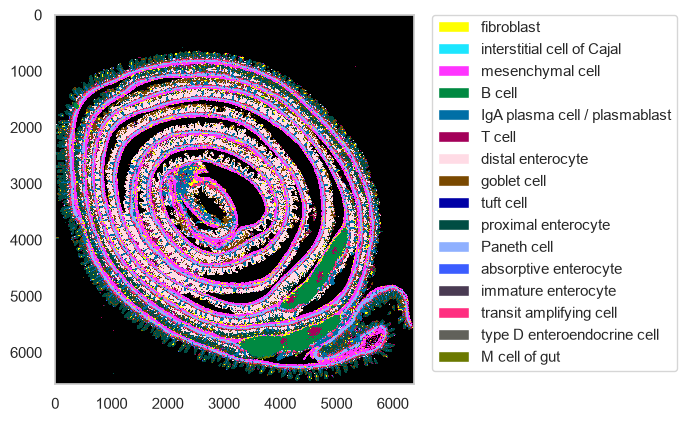

In [7]:
ds.plot_celltypes_map(show_annotation=True)

In [8]:
sdata_tsvm.write('/bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/visiumhd_small_intestine/map_tsvm.zarr')


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the